In [1]:
# Cell 0: Imports and settings -- WRF 111m multi-height wavelet, IOP10
# Mirrors wavelet_multiH_UWOW_750_500_250m_band45-90min_IOP10 for comparison
import numpy as np
import gc
import pycwt
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.dates as mdates
import os
from datetime import datetime, timedelta

plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['savefig.facecolor'] = 'white'

STATION       = 'UWLDR'
DOMAIN        = 'd04'
BASE_DIR      = '/home/voyager-sbarc/wrf/wrf460/sundowners/swex2022/iop10/run_1km_545_24_z107_2way/ndown_111m_km_opt2_2Dom'
PARTS         = ['partA', 'partB', 'partC', 'partD']
SIM_START_UTC = datetime(2022, 5, 12, 16, 0, 0)

UTCoffset = timedelta(hours=7)
IOP_start = datetime(2022, 5, 12, 10, 0, 0)   # PDT
IOP_end   = datetime(2022, 5, 13, 10, 0, 0)   # PDT -- matches UWOW observation window

TARGET_HEIGHTS = [750, 500, 250]   # [m AGL]
BAND_MIN       = 45                 # [min]
BAND_MAX       = 90                 # [min]

OUTDIR = '/home/voyager-sbarc/duine/sundowners/swex2022/analysis/analysis_IOP10/spectral_model/111m'

def tslist_path(var, part):
    return os.path.join(BASE_DIR, f'tslist_{DOMAIN}_{part}', f'{STATION}.{DOMAIN}.{var}')

print(f'Analysis window: {IOP_start} -- {IOP_end} PDT')
print(f'Target heights: {TARGET_HEIGHTS} m')

Analysis window: 2022-05-12 10:00:00 -- 2022-05-13 10:00:00 PDT
Target heights: [750, 500, 250] m


In [2]:
# Cell 1: tslist reader functions

def read_part(var, part):
    fpath = tslist_path(var, part)
    if not os.path.exists(fpath):
        print(f'  {part}: not found -- {fpath}')
        return None, None
    print(f'  Reading {var} {part} ...', end=' ', flush=True)
    raw  = np.loadtxt(fpath, skiprows=1)
    t_h  = raw[:, 0]
    data = raw[:, 1:]
    print(f'{len(t_h)} steps, {data.shape[1]} levels, t={t_h[0]:.4f}-{t_h[-1]:.4f} h')
    return t_h, data

def concat_parts(var, parts=PARTS):
    t_list, d_list = [], []
    for part in parts:
        t_h, data = read_part(var, part)
        if t_h is None:
            continue
        if t_list:
            mask = t_h > t_list[-1][-1]
            t_h  = t_h[mask]
            data = data[mask]
        if len(t_h) == 0:
            continue
        t_list.append(t_h)
        d_list.append(data)
    return np.concatenate(t_list), np.concatenate(d_list, axis=0)

def t_hours_to_pdt(t_h):
    return np.array([SIM_START_UTC - UTCoffset + timedelta(hours=float(h)) for h in t_h])

In [3]:
# Cell 2: Load PH and WW, compute heights AGL, filter to IOP10

print('=== PH (heights) ===')
t_ph, ph_all = concat_parts('PH')
ph_mean = np.mean(ph_all, axis=0)
h_agl   = ph_mean - ph_mean[0]
del ph_all
print(f'Height range: {h_agl[0]:.1f} to {h_agl[-1]:.0f} m AGL')
print(f'Lowest 5 levels [m]: {h_agl[:5].round(1)}')

print('\n=== WW (vertical velocity) ===')
t_ww, W_raw = concat_parts('WW')
t_pdt_all   = t_hours_to_pdt(t_ww)

dt_h   = float(np.median(np.diff(t_ww)))
dt_sec = dt_h * 3600
print(f'Model dt = {dt_sec:.3f} s')

keep  = (t_pdt_all >= IOP_start) & (t_pdt_all <= IOP_end)
t_pdt = t_pdt_all[keep]
W_wrf = W_raw[keep, :].T    # [nLev x nTime]
del W_raw, t_pdt_all
print(f'After IOP10 filter: {W_wrf.shape[1]} time steps ({W_wrf.shape[1]*dt_sec/3600:.2f} h)')

if W_wrf.shape[0] != len(h_agl):
    print(f'Level count: WW={W_wrf.shape[0]}, PH={len(h_agl)} -- trimming to min')
    n     = min(W_wrf.shape[0], len(h_agl))
    W_wrf = W_wrf[:n, :]
    h_agl = h_agl[:n]

print(f'Final W shape: {W_wrf.shape}  (nLev x nTime)')

=== PH (heights) ===
  Reading PH partA ... 96000 steps, 40 levels, t=0.0001-8.0000 h
  Reading PH partB ... 84000 steps, 40 levels, t=8.0001-15.0000 h
  Reading PH partC ... 108000 steps, 40 levels, t=15.0001-24.0000 h
  Reading PH partD ... 12000 steps, 40 levels, t=24.0001-25.0000 h
Height range: 0.0 to 6632 m AGL
Lowest 5 levels [m]: [  0.   41.8  74.4 111.5 153. ]

=== WW (vertical velocity) ===
  Reading WW partA ... 96000 steps, 40 levels, t=0.0001-8.0000 h
  Reading WW partB ... 84000 steps, 40 levels, t=8.0001-15.0000 h
  Reading WW partC ... 108000 steps, 40 levels, t=15.0001-24.0000 h
  Reading WW partD ... 12000 steps, 40 levels, t=24.0001-25.0000 h
Model dt = 0.299 s
After IOP10 filter: 288001 time steps (23.90 h)
Final W shape: (40, 288001)  (nLev x nTime)


  750 m target -> 728 m (gate 12)
  500 m target -> 535 m (gate 10)
  250 m target -> 253 m (gate 6)

CWT at 728 m (gate 12) ...
  done.

CWT at 535 m (gate 10) ...
ar1() failed -- using lag-1 autocorr: alpha = 0.9900
  done.

CWT at 253 m (gate 6) ...
ar1() failed -- using lag-1 autocorr: alpha = 0.9900
  done.

5-min smooth kernel: 1004 samples
Saved wavelet_multiH_WRF_111m_750_500_250m_band45-90min_IOP10.png
Saved wavelet_multiH_WRF_111m_750_500_250m_band45-90min_IOP10.pdf


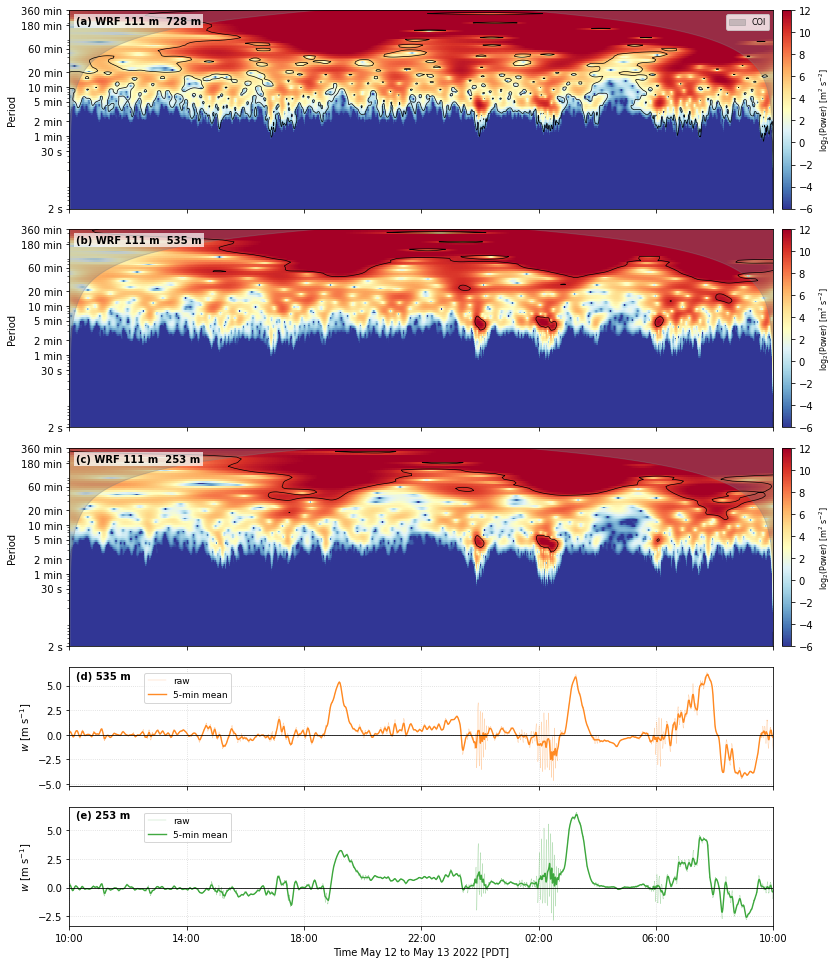

In [4]:
# Cell 3: 5-panel figure
# (a-c) scalograms at TARGET_HEIGHTS; (d) raw w at 500 m; (e) raw w at 250 m
# Memory: compute -> plot -> del per height to avoid accumulating CWT arrays

colors_band  = ['tab:blue', 'tab:orange', 'tab:green']
panel_labels = ['(a)', '(b)', '(c)', '(d)', '(e)']

n = len(TARGET_HEIGHTS)
height_ratios = [2.5] * n + [1.5, 1.5]
fig, axes = plt.subplots(n + 2, 1,
                         figsize=(13, 2.5 * n + 6),
                         gridspec_kw={'height_ratios': height_ratios},
                         sharex=True)
ax_scalo = axes[:n]
ax_w1    = axes[n]       # panel d: 500 m
ax_w2    = axes[n + 1]   # panel e: 250 m

# --- Regular time grid (fills micro-gaps at restart boundaries) ---
t_elapsed = np.array([(t - t_pdt[0]).total_seconds() for t in t_pdt])
t_reg     = np.arange(0.0, t_elapsed[-1] + dt_sec, dt_sec)
t_dt_reg  = np.array([t_pdt[0] + timedelta(seconds=float(s)) for s in t_reg])
t_num_reg = mdates.date2num(t_dt_reg)

# --- CWT settings ---
dj     = 0.125
s0     = 2.0 * dt_sec
J      = int(np.log2(len(t_reg) * dt_sec / s0) / dj)
mother = pycwt.Morlet(6)

# --- Gate indices ---
gate_indices = {h: int(np.argmin(np.abs(h_agl - h))) for h in TARGET_HEIGHTS}
for h in TARGET_HEIGHTS:
    print(f'  {h} m target -> {h_agl[gate_indices[h]]:.0f} m (gate {gate_indices[h]})')

# --- Panels a-c: scalograms ---
for ax, h_tgt, color, plabel in zip(ax_scalo, TARGET_HEIGHTS, colors_band, panel_labels[:n]):
    g = gate_indices[h_tgt]
    h = h_agl[g]
    print(f'\nCWT at {h:.0f} m (gate {g}) ...')

    w_g    = W_wrf[g, :].astype(float)
    w_cont = np.interp(t_reg, t_elapsed, w_g)
    w_cont -= w_cont.mean()

    wave, scales, freqs_wav, coi, _, _ = pycwt.cwt(w_cont, dt_sec, dj, s0, J, mother)
    power = np.abs(wave)**2
    del wave
    period_min = 1.0 / freqs_wav / 60
    coi_min    = coi / 60

    try:
        alpha, _, _ = pycwt.ar1(w_cont)
    except Warning:
        alpha = float(np.corrcoef(w_cont[:-1], w_cont[1:])[0, 1])
        alpha = max(0.0, min(alpha, 0.99))
        print(f'ar1() failed -- using lag-1 autocorr: alpha = {alpha:.4f}')
    signif, _ = pycwt.significance(w_cont.std()**2, dt_sec, scales, 0, alpha,
                                    significance_level=0.95, wavelet=mother)
    sig95 = power / signif[:, np.newaxis]
    del w_cont, signif

    pcm = ax.pcolormesh(t_num_reg, period_min, np.log2(np.maximum(power, 1e-10)),
                        shading='nearest', cmap='RdYlBu_r', vmin=-6, vmax=12, rasterized=True)
    ax.xaxis_date()
    ax.contour(t_dt_reg, period_min, sig95, levels=[1.0], colors='k', linewidths=0.7)
    ax.fill_between(t_dt_reg, coi_min, period_min[-1], color='grey', alpha=0.35, label='COI')
    ax.axhspan(BAND_MIN, BAND_MAX, color='gold', alpha=0.2, zorder=0)
    ax.set_yscale('log')
    ax.yaxis.set_major_formatter(mticker.ScalarFormatter())
    ax.set_yticks([2/60, 0.5, 1, 2, 5, 10, 20, 60, 180, 360])
    ax.set_yticklabels(['2 s', '30 s', '1 min', '2 min', '5 min',
                        '10 min', '20 min', '60 min', '180 min', '360 min'])
    ax.set_ylim([2/60, 360])
    ax.set_ylabel('Period')
    cb = fig.colorbar(pcm, ax=ax, pad=0.01, aspect=20)
    cb.set_label(r'log$_2$(Power) [m$^2$ s$^{-2}$]', fontsize=8)
    ax.text(0.01, 0.97, f'{plabel} WRF 111 m  {h:.0f} m',
            transform=ax.transAxes, va='top', ha='left', fontsize=10, fontweight='bold',
            bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=2))

    del power, sig95
    gc.collect()
    print('  done.')

ax_scalo[0].legend(loc='upper right', fontsize=8)

# --- Panels d-e: raw w + 5-min mean ---
smooth_n = int(round(300.0 / dt_sec))   # 5-min smoothing kernel in samples
print(f'\n5-min smooth kernel: {smooth_n} samples')

def plot_w_panel(ax, h_tgt, color, plabel):
    g        = gate_indices[h_tgt]
    h        = h_agl[g]
    t_pdt_n  = mdates.date2num(t_pdt)
    w_raw    = W_wrf[g, :].astype(float)
    idx_all  = np.arange(len(w_raw), dtype=float)
    valid    = np.isfinite(w_raw)
    w_interp = np.interp(idx_all, idx_all[valid], w_raw[valid])
    w_smooth = np.convolve(w_interp, np.ones(smooth_n) / smooth_n, mode='same')
    ax.plot(t_pdt_n, w_raw,    color=color, lw=0.4, alpha=0.4, label='raw')
    ax.plot(t_pdt_n, w_smooth, color=color, lw=1.4, alpha=0.9, label='5-min mean')
    ax.axhline(0, color='k', lw=0.8)
    ax.set_ylabel(r'$w$ [m s$^{-1}$]')
    ax.grid(True, ls=':', alpha=0.5)
    ax.legend(loc='upper left', bbox_to_anchor=(0.10, 0.99), fontsize=9)
    ax.text(0.01, 0.97, f'{plabel} {h:.0f} m', transform=ax.transAxes,
            va='top', ha='left', fontsize=10, fontweight='bold')

plot_w_panel(ax_w1, TARGET_HEIGHTS[1], colors_band[1], '(d)')
plot_w_panel(ax_w2, TARGET_HEIGHTS[2], colors_band[2], '(e)')

ax_w2.set_xlabel('Time May 12 to May 13 2022 [PDT]')
ax_w2.xaxis_date()
ax_w2.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
ax_w2.xaxis.set_major_locator(mdates.HourLocator(byhour=[2, 6, 10, 14, 18, 22]))

fig.tight_layout()

# Align right edges of w panels to scalogram width (colorbars narrow scalograms)
pos_ref = ax_scalo[-1].get_position()
for ax in list(ax_scalo) + [ax_w1, ax_w2]:
    p = ax.get_position()
    ax.set_position([pos_ref.x0, p.y0, pos_ref.width, p.height])

fname_base = (f'wavelet_multiH_WRF_111m_'
              f'{"_".join(str(h) for h in TARGET_HEIGHTS)}m_'
              f'band{BAND_MIN}-{BAND_MAX}min_IOP10')
os.makedirs(OUTDIR, exist_ok=True)
for ext, kw in [('png', {'dpi': 150}), ('pdf', {'dpi': 300})]:
    fig.savefig(os.path.join(OUTDIR, f'{fname_base}.{ext}'), bbox_inches='tight', **kw)
    print(f'Saved {fname_base}.{ext}')

plt.show()